# 5. Monte Carlo, model risk and delta hedging
Three experiments. First, Monte Carlo done properly: how its error shrinks and how to make it smaller. Second, the Heston and Merton models from notebook 4 used to price an exotic option, where the models stop agreeing. Third, what actually happens to a trader who sells an option and delta hedges it.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

os.makedirs("figures", exist_ok=True)


def bs_price(F, K, T, r, sigma, option_type):
    D = np.exp(-r * T)
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        return D * (F * norm.cdf(d1) - K * norm.cdf(d2))
    else:
        return D * (K * norm.cdf(-d2) - F * norm.cdf(-d1))


# test case: at-the-money March 2027 call at 15% vol
F = 785.28
K = 785.0
T = 0.4767
r = 0.0396
sigma = 0.15
exact = bs_price(F, K, T, r, sigma, "call")  # the answer Monte Carlo should hit
print(f"Black-Scholes formula price: {exact:.4f}")

Black-Scholes formula price: 31.9560


An option price is a discounted average of payoffs, and Monte Carlo replaces the true average with the average over N simulated futures. Its error is the standard error, std(payoff) / √N, so 100 times more paths only buy 10 times less error. I check that against the exact Black-Scholes price.

     N       MC price   std error   true error
      100     31.0999     5.0767     -0.8561
    1,000     33.3888     1.5641     +1.4328
   10,000     32.2200     0.4985     +0.2640
  100,000     31.8942     0.1566     -0.0618
1,000,000     31.9668     0.0496     +0.0108


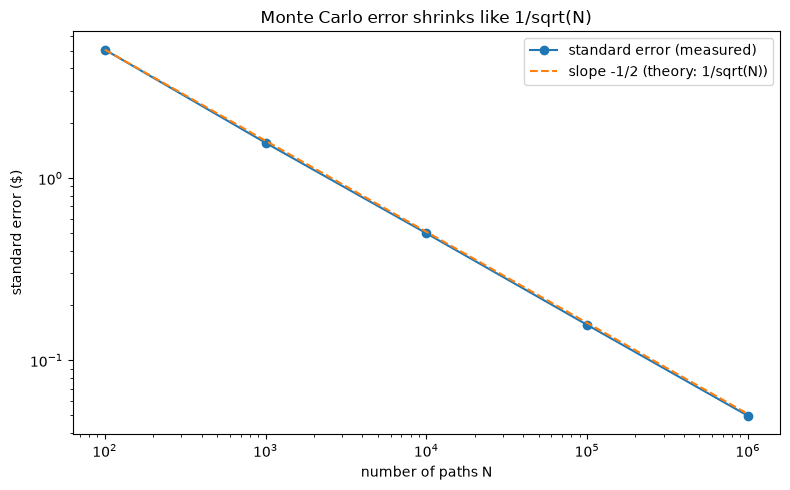

In [2]:
def mc_call_plain(n_paths, rng):
    Z = rng.standard_normal(n_paths)
    F_T = F * np.exp(-0.5 * sigma**2 * T + sigma * np.sqrt(T) * Z)
    payoff = np.exp(-r * T) * np.maximum(F_T - K, 0)
    return payoff.mean(), payoff.std() / np.sqrt(n_paths)


rng = np.random.default_rng(3)
sizes = [100, 1_000, 10_000, 100_000, 1_000_000]
plain_se = []
print("     N       MC price   std error   true error")
for n in sizes:
    price, se = mc_call_plain(n, rng)
    plain_se.append(se)
    print(f"{n:>9,}   {price:9.4f}   {se:8.4f}   {price - exact:+9.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(sizes, plain_se, marker="o", label="standard error (measured)")
ax.loglog(sizes, plain_se[0] * np.sqrt(sizes[0] / np.array(sizes)), linestyle="--", label="slope -1/2 (theory: 1/sqrt(N))")
ax.set_xlabel("number of paths N")
ax.set_ylabel("standard error ($)")
ax.set_title("Monte Carlo error shrinks like 1/sqrt(N)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/09_mc_convergence.png", dpi=150)
plt.show()

The standard error falls from $5.08 to $0.05 across four orders of magnitude, exactly on the 1/√N line, and the true error stays within about two standard errors each time.

More paths is the slow way. The other way is to reduce the variance of the payoffs:
- Antithetic paths: use every random draw twice, as Z and -Z. A high future and a low future get averaged together, which cancels part of the noise.
- Control variate: F_T has a known average (F, because the forward is a martingale). On each path I see how far F_T missed F and correct the payoff by b times that miss. b is the regression slope of the payoff on F_T, so the correction is zero on average and only removes noise.

In [3]:
def mc_call_antithetic(n_paths, rng):
    Z = rng.standard_normal(n_paths // 2)  # half the draws, each used twice
    F_up = F * np.exp(-0.5 * sigma**2 * T + sigma * np.sqrt(T) * Z)
    F_down = F * np.exp(-0.5 * sigma**2 * T - sigma * np.sqrt(T) * Z)
    pair_avg = 0.5 * np.exp(-r * T) * (np.maximum(F_up - K, 0) + np.maximum(F_down - K, 0))
    # the pairs are independent of each other, so the standard error uses the number of pairs
    return pair_avg.mean(), pair_avg.std() / np.sqrt(len(pair_avg))


def mc_call_control(n_paths, rng):
    Z = rng.standard_normal(n_paths)
    F_T = F * np.exp(-0.5 * sigma**2 * T + sigma * np.sqrt(T) * Z)
    payoff = np.exp(-r * T) * np.maximum(F_T - K, 0)
    control = F_T - F  # known to average zero
    b = np.cov(payoff, control)[0, 1] / control.var()
    adjusted = payoff - b * control
    corr = np.corrcoef(payoff, control)[0, 1]
    return adjusted.mean(), adjusted.std() / np.sqrt(n_paths), b, corr


n = 100_000  # same number of random numbers for every method
rng = np.random.default_rng(7)
p_plain, se_plain = mc_call_plain(n, rng)
p_anti, se_anti = mc_call_antithetic(n, rng)
p_cv, se_cv, b, corr = mc_call_control(n, rng)

print(f"Exact price: {exact:.4f}   (all methods use {n:,} random numbers)")
print(f"Plain        {p_plain:.4f}  +/- {se_plain:.4f}")
print(f"Antithetic   {p_anti:.4f}  +/- {se_anti:.4f}   variance cut by {(se_plain / se_anti)**2:.1f}x")
print(f"Control var. {p_cv:.4f}  +/- {se_cv:.4f}   variance cut by {(se_plain / se_cv)**2:.1f}x   (b = {b:.3f}, correlation = {corr:.3f})")

Exact price: 31.9560   (all methods use 100,000 random numbers)
Plain        31.8105  +/- 0.1563
Antithetic   32.0263  +/- 0.1205   variance cut by 1.7x
Control var. 31.9206  +/- 0.0757   variance cut by 4.3x   (b = 0.533, correlation = 0.876)


Antithetic cuts the variance 1.7 times, the control variate 4.3 times, for free. A 4.3x variance cut is worth 4.3 times more paths. The control variate wins because the call payoff is strongly correlated with F_T (theory says the cut is 1/(1-ρ²)), and b ≈ 0.53 is close to the call's delta: it's effectively a delta hedge inside the simulation.

## Model risk: a barrier option
In notebook 4, Heston and Merton both fitted the vanilla market reasonably. Do they agree on an exotic? I price a down-and-out put on the March 2027 expiry: strike 785, and it dies if SPY touches 700 at any point before expiry. Its value depends on the path, not just on where SPY ends, so I simulate 480 steps per path (about 4 per trading day) under Black-Scholes, Heston and Merton, each with its parameters from the real data.

In [4]:
options = pd.read_csv("spy_surface_clean_2026-10-08.csv")
march = options[options["expiry"] == "2027-03-31"]
F = march["F"].iloc[0]
T = march["T"].iloc[0]
r = march["r"].iloc[0]
K = 785.0
B = 700.0  # the barrier

# Black-Scholes uses the market vol at the strike closest to K
atm_row = march.iloc[(march["strike"] - K).abs().argmin()]
sigma_bs = atm_row["iv"]

# fitted parameters saved in notebook 4
v0, kappa, theta, xi, rho = np.load("heston_params.npy")
sigma_m, lam, muJ, delta = np.load("merton_params.npy")

print(f"F = {F:.2f}   T = {T:.4f}   r = {r:.4f}   strike K = {K:.0f}   barrier B = {B:.0f} ({B / F - 1:.1%} below F)")
print(f"Black-Scholes vol = market iv at strike {atm_row['strike']:.0f}: {sigma_bs:.2%}")

F = 785.28   T = 0.4767   r = 0.0401   strike K = 785   barrier B = 700 (-10.9% below F)
Black-Scholes vol = market iv at strike 785: 15.00%


Black-Scholes done in 2 s
Heston done in 4 s
Merton done in 5 s

Market price of the 785 put: 31.68
               vanilla put    +/-  down-and-out put   +/-   knocked out
model                                                                  
Black-Scholes       31.813  0.139             8.290  0.055        0.271
Heston              32.100  0.217             3.056  0.032        0.301
Merton              30.491  0.173             9.210  0.057        0.191


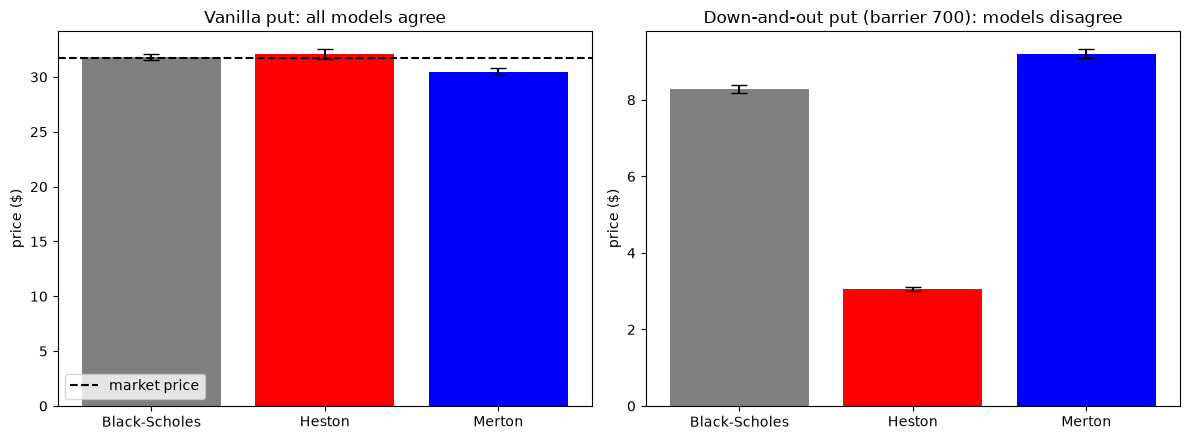

In [5]:
def simulate_put_and_barrier(model, n_paths, n_steps, rng):
    dt = T / n_steps
    logF = np.full(n_paths, np.log(F))
    lowest = np.full(n_paths, F)  # lowest level each path has reached so far
    if model == "Heston":
        v = np.full(n_paths, v0)
    if model == "Merton":
        m = np.exp(muJ + 0.5 * delta**2) - 1
    for step in range(n_steps):
        z1 = rng.standard_normal(n_paths)
        if model == "Black-Scholes":
            logF += -0.5 * sigma_bs**2 * dt + sigma_bs * np.sqrt(dt) * z1
        elif model == "Heston":
            z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(n_paths)
            v_pos = np.maximum(v, 0)  # full truncation, as in notebook 4
            logF += -0.5 * v_pos * dt + np.sqrt(v_pos * dt) * z1
            v += kappa * (theta - v_pos) * dt + xi * np.sqrt(v_pos * dt) * z2
        elif model == "Merton":
            n_jumps = rng.poisson(lam * dt, n_paths)
            jumps = muJ * n_jumps + delta * np.sqrt(n_jumps) * rng.standard_normal(n_paths)
            logF += (-lam * m - 0.5 * sigma_m**2) * dt + sigma_m * np.sqrt(dt) * z1 + jumps
        lowest = np.minimum(lowest, np.exp(logF))
    F_T = np.exp(logF)
    alive = lowest > B  # never touched the barrier
    D = np.exp(-r * T)
    vanilla = D * np.maximum(K - F_T, 0)
    barrier = vanilla * alive
    return vanilla, barrier, alive


rng = np.random.default_rng(11)
n_paths = 100_000
n_steps = 480

rows = []
for model in ["Black-Scholes", "Heston", "Merton"]:
    t0 = time.time()
    vanilla, barrier, alive = simulate_put_and_barrier(model, n_paths, n_steps, rng)
    rows.append({
        "model": model,
        "vanilla put": vanilla.mean(),
        "+/-": vanilla.std() / np.sqrt(n_paths),
        "down-and-out put": barrier.mean(),
        "+/- ": barrier.std() / np.sqrt(n_paths),  # trailing space keeps the column name unique
        "knocked out": 1 - alive.mean(),
    })
    print(f"{model} done in {time.time() - t0:.0f} s")
results = pd.DataFrame(rows).set_index("model")

# the market put price, via put-call parity if the closest quote is a call
market_put = atm_row["mid"] if atm_row["type"] == "put" else atm_row["mid"] - np.exp(-r * T) * (F - atm_row["strike"])
print(f"\nMarket price of the {atm_row['strike']:.0f} put: {market_put:.2f}")
print(results.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(results.index, results["vanilla put"], yerr=2 * results["+/-"], color=["gray", "red", "blue"], capsize=6)
axes[0].axhline(market_put, color="black", linestyle="--", label="market price")
axes[0].set_title("Vanilla put: all models agree")
axes[0].set_ylabel("price ($)")
axes[0].legend()
axes[1].bar(results.index, results["down-and-out put"], yerr=2 * results["+/- "], color=["gray", "red", "blue"], capsize=6)
axes[1].set_title(f"Down-and-out put (barrier {B:.0f}): models disagree")
axes[1].set_ylabel("price ($)")
plt.tight_layout()
plt.savefig("figures/10_model_risk_barrier.png", dpi=150)
plt.show()

The vanilla put costs about $30.5 to $32 under all three models, close to the market. The barrier put costs $8.29 under Black-Scholes, $3.06 under Heston and $9.21 under Merton, a factor of three apart, for models that all fit the vanilla market.

The reason is how each model gets SPY down to low levels. In Heston, vol rises as the price falls (ρ = -0.69), so paths that end deep in the money usually got there in a volatile slide that crossed 700 on the way: the put is worth most exactly when it has been knocked out. In Merton, normal moves are calm (12.6% vol) and big falls happen in one jump, so fewer paths drift into the barrier (19% knocked out vs 30% in Heston). The vanilla prices only pin down the distribution of where SPY ends, not the path it takes. That gap is model risk, and it's why exotic desks hold reserves against it.

## Delta hedging
I sell the March 2027 at-the-money call at 15% vol and delta hedge it with the forward until expiry, then look at the final P&L across 20,000 simulated paths. I set r = 0 so the cash account earns nothing and the bookkeeping stays simple; it doesn't change the lessons.

Experiment 1: in a Black-Scholes world with the right vol, hedging should replicate the option exactly as you rebalance more often.

Premium received for the call (15% vol, r = 0): 32.565

rebalances   mean P&L   std of P&L
         6     +0.107     10.869
        30     +0.036      5.051
       120     +0.015      2.579
       480     +0.007      1.302


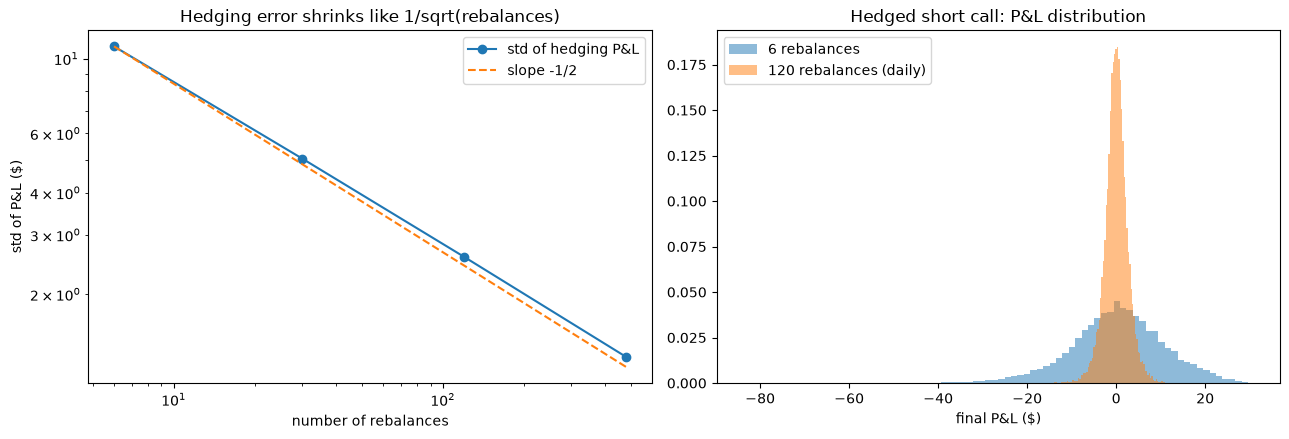

In [6]:
F = 785.28
T = 0.4767
K = 785.0


def call_price_r0(F_now, tau, sigma):
    d1 = (np.log(F_now / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return F_now * norm.cdf(d1) - K * norm.cdf(d2)


def call_delta_r0(F_now, tau, sigma):
    d1 = (np.log(F_now / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return norm.cdf(d1)


def simulate_paths(model, sigma_true, n_paths, n_steps, rng):
    # rows = paths, columns = time steps
    dt = T / n_steps
    logF = np.zeros((n_paths, n_steps + 1))
    logF[:, 0] = np.log(F)
    m = np.exp(muJ + 0.5 * delta**2) - 1
    for i in range(n_steps):
        z = rng.standard_normal(n_paths)
        if model == "Black-Scholes":
            logF[:, i + 1] = logF[:, i] - 0.5 * sigma_true**2 * dt + sigma_true * np.sqrt(dt) * z
        elif model == "Merton":
            n_jumps = rng.poisson(lam * dt, n_paths)
            jumps = muJ * n_jumps + delta * np.sqrt(n_jumps) * rng.standard_normal(n_paths)
            logF[:, i + 1] = logF[:, i] + (-lam * m - 0.5 * sigma_m**2) * dt + sigma_m * np.sqrt(dt) * z + jumps
    return np.exp(logF)


def hedge_pnl(paths, n_rebalance, sigma_hedge):
    # sell the call at sigma_hedge, hold delta forwards, rebalance n_rebalance times, pay the payoff
    n_steps = paths.shape[1] - 1
    every = n_steps // n_rebalance
    times = np.linspace(0, T, n_steps + 1)
    premium = call_price_r0(F, T, sigma_hedge)
    pnl = np.full(paths.shape[0], premium)
    for i in range(0, n_steps, every):
        hedge = call_delta_r0(paths[:, i], T - times[i], sigma_hedge)
        pnl += hedge * (paths[:, i + every] - paths[:, i])
    pnl -= np.maximum(paths[:, -1] - K, 0)
    return pnl


rng = np.random.default_rng(5)
n_paths = 20_000
n_steps = 480  # 4 steps per trading day
sigma_imp = 0.15

bs_paths = simulate_paths("Black-Scholes", sigma_imp, n_paths, n_steps, rng)
print(f"Premium received for the call (15% vol, r = 0): {call_price_r0(F, T, sigma_imp):.3f}\n")

rebalances = [6, 30, 120, 480]  # monthly, weekly, daily, 4 times a day
stds = []
print("rebalances   mean P&L   std of P&L")
for n in rebalances:
    pnl = hedge_pnl(bs_paths, n, sigma_imp)
    stds.append(pnl.std())
    print(f"{n:>10}   {pnl.mean():+8.3f}   {pnl.std():8.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(rebalances, stds, marker="o", label="std of hedging P&L")
axes[0].loglog(rebalances, stds[0] * np.sqrt(rebalances[0] / np.array(rebalances)), linestyle="--", label="slope -1/2")
axes[0].set_xlabel("number of rebalances")
axes[0].set_ylabel("std of P&L ($)")
axes[0].set_title("Hedging error shrinks like 1/sqrt(rebalances)")
axes[0].legend()
axes[1].hist(hedge_pnl(bs_paths, 6, sigma_imp), bins=80, alpha=0.5, density=True, label="6 rebalances")
axes[1].hist(hedge_pnl(bs_paths, 120, sigma_imp), bins=80, alpha=0.5, density=True, label="120 rebalances (daily)")
axes[1].set_xlabel("final P&L ($)")
axes[1].set_title("Hedged short call: P&L distribution")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/11_hedging_error.png", dpi=150)
plt.show()

The average P&L is zero and the spread halves every time rebalancing goes up 4 times (10.87, 5.05, 2.58, 1.30), the same 1/√N law as Monte Carlo. With continuous hedging it would reach zero, which is the replication argument behind the Black-Scholes formula.

Experiment 2: I sell at 15% vol, but the market actually moves at 12% or 18%.

In [7]:
print("Sold at 15% vol, hedged daily (120 rebalances), but the market really moves with:")
print("realised vol   mean P&L    std     theory C(15%) - C(realised)")
for sigma_true in [0.12, 0.15, 0.18]:
    paths = simulate_paths("Black-Scholes", sigma_true, n_paths, n_steps, rng)
    pnl = hedge_pnl(paths, 120, sigma_imp)
    theory = call_price_r0(F, T, sigma_imp) - call_price_r0(F, T, sigma_true)
    print(f"{sigma_true:>10.0%}   {pnl.mean():+8.3f}   {pnl.std():6.3f}   {theory:+8.3f}")

Sold at 15% vol, hedged daily (120 rebalances), but the market really moves with:
realised vol   mean P&L    std     theory C(15%) - C(realised)
       12%     +6.481    2.969     +6.481
       15%     +0.044    2.551     +0.000
       18%     -6.472    4.088     -6.477


The hedged trader doesn't care where SPY goes, only how much it moves. If realised vol is 12%, they keep +$6.48; at 18% they lose $6.47, exactly the difference between the option priced at the two vols. A delta-hedged short option is a bet that realised vol stays below implied vol. That's the starting point for the VIX section below.

Experiment 3: the market follows Merton's jump model, fitted to SPY in notebook 4. I price the call at the Black-Scholes vol that matches its true Merton value, so on average the trade is fair, and hedge as before.

Merton world: fair call value 31.436  ->  Black-Scholes vol that matches it: 14.48%
rebalances   mean P&L   std    worst 1%   worst path
         6     +0.200  23.857   -120.31    -381.41
        30     +0.146  23.270   -128.51    -382.38
       120     +0.155  22.975   -126.88    -392.45
       480     +0.166  22.991   -126.89    -392.23

Paths with a jump: 4.7%   average daily-hedged P&L on them: -78.27   on the rest: +4.02


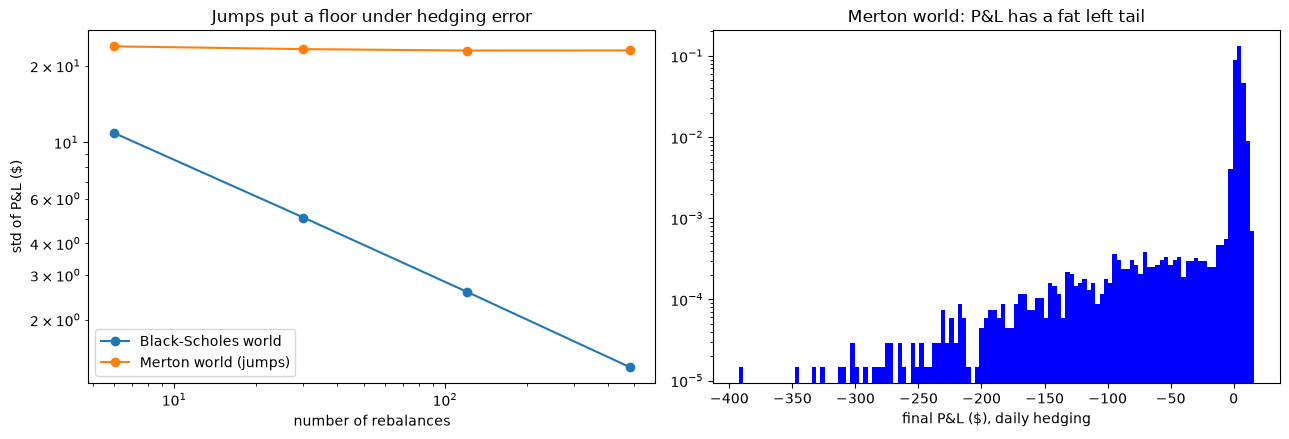

In [8]:
merton_paths = simulate_paths("Merton", None, n_paths, n_steps, rng)
merton_value = np.maximum(merton_paths[:, -1] - K, 0).mean()
sigma_fair = brentq(lambda s: call_price_r0(F, T, s) - merton_value, 0.01, 1.0)
print(f"Merton world: fair call value {merton_value:.3f}  ->  Black-Scholes vol that matches it: {sigma_fair:.2%}")

print("rebalances   mean P&L   std    worst 1%   worst path")
merton_stds = []
for n in rebalances:
    pnl = hedge_pnl(merton_paths, n, sigma_fair)
    merton_stds.append(pnl.std())
    print(f"{n:>10}   {pnl.mean():+8.3f}  {pnl.std():6.3f}  {np.percentile(pnl, 1):8.2f}   {pnl.min():8.2f}")

# a path "jumped" if any single step moved more than 5%, which a normal step basically never does
jumped = (np.abs(np.diff(np.log(merton_paths), axis=1)) > 0.05).any(axis=1)
pnl_daily = hedge_pnl(merton_paths, 120, sigma_fair)
print(f"\nPaths with a jump: {jumped.mean():.1%}   average daily-hedged P&L on them: {pnl_daily[jumped].mean():+.2f}   on the rest: {pnl_daily[~jumped].mean():+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(rebalances, stds, marker="o", label="Black-Scholes world")
axes[0].loglog(rebalances, merton_stds, marker="o", label="Merton world (jumps)")
axes[0].set_xlabel("number of rebalances")
axes[0].set_ylabel("std of P&L ($)")
axes[0].set_title("Jumps put a floor under hedging error")
axes[0].legend()
axes[1].hist(pnl_daily, bins=120, density=True, color="blue")
axes[1].set_yscale("log")
axes[1].set_xlabel("final P&L ($), daily hedging")
axes[1].set_title("Merton world: P&L has a fat left tail")
plt.tight_layout()
plt.savefig("figures/12_hedging_jumps.png", dpi=150)
plt.show()

Rebalancing more often doesn't help: the spread stays around 23 dollars whether I hedge monthly or four times a day. A jump happens between two rebalances, so no delta can be in place for it. 4.7% of paths had a jump and lost 78 dollars on average; the other 95% made about +4 dollars each. Selling options in a world with jumps looks like steady small profits with a rare large loss, which is why the market charges extra for crash protection and why the skew exists.

# Variance risk premium: is selling volatility profitable in reality?
Experiment 2 showed that a hedged option seller earns implied minus realised vol. The VIX is the market's implied vol for the S&P 500 over the next 30 days (21 trading days). I compare it with the vol that actually happened over those 21 days, every day since 1990. I use the S&P 500 index (^GSPC) rather than SPY because the VIX is computed on the index and the history goes back further.

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

os.makedirs("figures", exist_ok=True)

# end date fixed so a rerun gives the same data
raw = yf.download(["^GSPC", "^VIX"], start="1990-01-01", end="2026-10-10", auto_adjust=True, progress=False)
prices = raw["Close"].dropna()
print(f"{len(prices)} days from {prices.index[0].date()} to {prices.index[-1].date()}")
print(prices.head())
print(prices.tail())
prices.to_csv("sp500_vix_daily.csv")

9261 days from 1990-01-02 to 2026-10-09
Ticker           ^GSPC       ^VIX
Date                             
1990-01-02  359.690002  17.240000
1990-01-03  358.760010  18.190001
1990-01-04  355.670013  19.219999
1990-01-05  352.200012  20.110001
1990-01-08  353.790009  20.260000
Ticker            ^GSPC   ^VIX
Date                          
2026-10-05  7773.950195  15.52
2026-10-06  7818.930176  15.01
2026-10-07  7801.770020  15.08
2026-10-08  7765.359863  15.41
2026-10-09  7811.540039  14.84


Realised vol for day t uses the 21 daily log returns that come after t, annualised with 252 days: 100·√(252/21 · Σr²). The shift(-21) makes each day look forward, so the VIX on a day is compared with what happened next, not with the past.

In [10]:
returns = np.log(prices["^GSPC"]).diff()
squared = returns**2
next_21_sum = squared.rolling(21).sum().shift(-21)  # sum of the next 21 days, not the last 21

data = pd.DataFrame({
    "VIX": prices["^VIX"],
    "realised_vol": 100 * np.sqrt(252 / 21 * next_21_sum),
})
data = data.dropna()  # the last 21 days have no future yet
data["VRP"] = data["VIX"] - data["realised_vol"]

print(data.describe().round(2))
print(f"\nVIX above realised vol on {(data['VRP'] > 0).mean():.1%} of days")

           VIX  realised_vol      VRP
count  9240.00       9240.00  9240.00
mean     19.44         15.33     4.10
std       7.73          9.42     6.61
min       9.14          3.80   -71.96
25%      13.99          9.71     2.22
50%      17.59         12.94     4.71
75%      22.69         18.25     7.22
max      82.69         95.56    30.77

VIX above realised vol on 85.9% of days


The VIX averages 19.4 while realised vol averages 15.3, so implied vol is about 4 points too high on average, and higher on 86% of days. That gap is the variance risk premium (VRP).

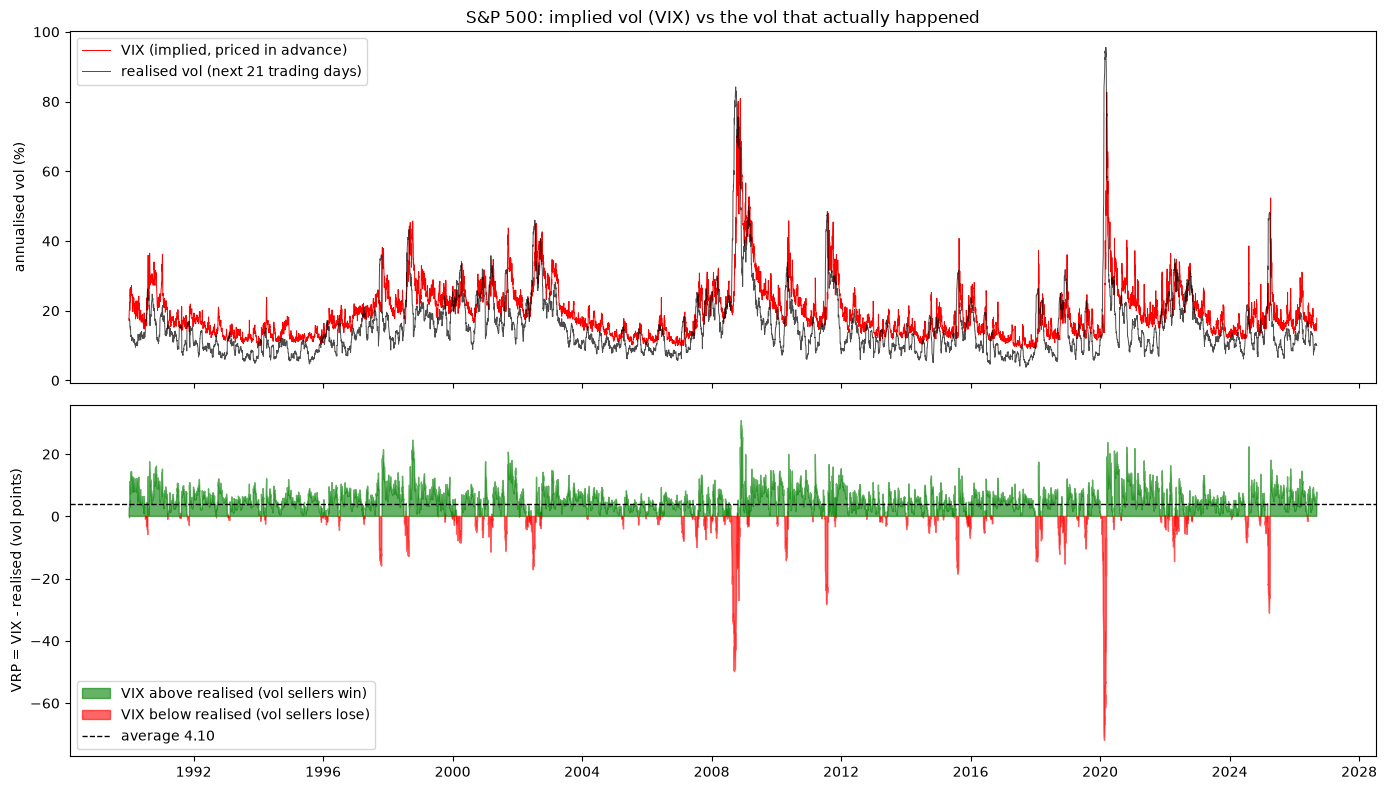

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(data.index, data["VIX"], color="red", linewidth=0.7, label="VIX (implied, priced in advance)")
axes[0].plot(data.index, data["realised_vol"], color="black", linewidth=0.7, alpha=0.7, label="realised vol (next 21 trading days)")
axes[0].set_ylabel("annualised vol (%)")
axes[0].set_title("S&P 500: implied vol (VIX) vs the vol that actually happened")
axes[0].legend(loc="upper left")

axes[1].fill_between(data.index, data["VRP"], 0, where=data["VRP"] >= 0, color="green", alpha=0.6, label="VIX above realised (vol sellers win)")
axes[1].fill_between(data.index, data["VRP"], 0, where=data["VRP"] < 0, color="red", alpha=0.6, label="VIX below realised (vol sellers lose)")
axes[1].axhline(data["VRP"].mean(), color="black", linestyle="--", linewidth=1, label=f"average {data['VRP'].mean():.2f}")
axes[1].set_ylabel("VRP = VIX - realised (vol points)")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig("figures/13_vix_vs_realised.png", dpi=150)
plt.show()

In [12]:
print("5 worst days for a vol seller (VIX far below what happened next):")
print(data.nsmallest(5, "VRP").round(2).to_string())
print("\n5 best days for a vol seller:")
print(data.nlargest(5, "VRP").round(2).to_string())

by_year = data.groupby(data.index.year)[["VIX", "realised_vol", "VRP"]].mean().round(2)
by_year["share positive"] = data.groupby(data.index.year)["VRP"].apply(lambda v: (v > 0).mean()).round(2)
print("\nAverage by year:")
print(by_year.to_string())

# variance swaps pay in variance, which punishes large moves much more
data["variance_VRP"] = data["VIX"]**2 - data["realised_vol"]**2
print(f"\nIn vol points:      average VRP {data['VRP'].mean():.2f},  median {data['VRP'].median():.2f}")
print(f"In variance units:  average {data['variance_VRP'].mean():.1f},  median {data['variance_VRP'].median():.1f},  worst {data['variance_VRP'].min():.0f}")

5 worst days for a vol seller (VIX far below what happened next):
              VIX  realised_vol    VRP
Date                                  
2020-02-20  15.56         87.52 -71.96
2020-02-19  14.38         86.18 -71.80
2020-02-18  14.83         86.18 -71.35
2020-02-21  17.08         88.05 -70.97
2020-02-14  13.68         84.19 -70.51

5 best days for a vol seller:
              VIX  realised_vol    VRP
Date                                  
2008-12-01  68.51         37.74  30.77
2008-12-04  63.64         34.38  29.26
2008-12-09  58.91         30.99  27.92
2008-12-08  58.49         31.15  27.34
2008-12-05  59.93         33.75  26.18

Average by year:
        VIX  realised_vol   VRP  share positive
Date                                           
1990  23.06         15.40  7.66            0.93
1991  18.38         13.55  4.84            0.89
1992  15.45          9.39  6.06            1.00
1993  12.69          8.34  4.35            0.95
1994  13.93          9.55  4.37            0.94
199

The pattern from the Merton hedging experiment shows up in real data. The premium is positive in every year except 2008, but the losses come in short, violent bursts: the five worst days are all in late February 2020, just before the COVID crash, when the VIX was around 15 and realised vol turned out to be over 85. In variance terms the median gain is 125 but the worst single day is -8,160.

Why does the premium exist? Under the risk-neutral measure Q, option prices include compensation for bearing crash risk, so the VIX is an expectation under Q, while realised vol happens under the real-world measure P. Investors pay up for protection against market crashes, and option sellers demand that premium because their losses arrive exactly when everything else is falling.

In [13]:
data.to_csv("vix_realised_vrp.csv")
by_year.to_csv("vrp_by_year.csv")
print("saved")

saved
